In [1]:
# Import required libraries
#project1

import pandas as pd
import numpy as np

# Libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Libraries for machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Creating a sample student performance dataset
# In a real-world project, this data can be collected from
# college/school records.

data = {
    'Attendance': [85, 90, 75, 95, 60, 80, 88, 70, 92, 65,
                   78, 84, 96, 72, 89, 55, 81, 93, 68, 87,
                   76, 91, 73, 86, 64, 79, 94, 69, 83, 77],

    'Internal_Marks': [78, 85, 65, 92, 55, 72, 80, 60, 88, 58,
                       70, 76, 95, 63, 84, 50, 74, 90, 57, 82,
                       68, 87, 61, 79, 54, 71, 93, 59, 77, 69],

    'Assignment_Marks': [82, 88, 70, 95, 52, 75, 85, 65, 90, 60,
                         73, 80, 97, 68, 86, 48, 78, 92, 62, 84,
                         71, 89, 66, 81, 56, 74, 94, 64, 79, 72],

    'Study_Hours': [6, 7, 4, 8, 3, 5, 6, 3, 7, 4,
                    5, 6, 9, 4, 7, 2, 5, 8, 3, 6,
                    4, 7, 4, 6, 3, 5, 8, 3, 6, 5],

    'Previous_Semester_Marks': [75, 82, 62, 90, 50, 70, 78, 58, 85, 55,
                                68, 74, 92, 60, 80, 45, 72, 88, 54, 79,
                                65, 84, 59, 76, 51, 69, 91, 57, 73, 67],

    'Final_Marks': [79, 86, 67, 93, 53, 73, 81, 62, 88, 59,
                    71, 78, 94, 64, 83, 49, 75, 91, 59, 82,
                    69, 86, 63, 80, 55, 72, 93, 61, 77, 70]
}

# Convert dictionary into a Pandas DataFrame
df = pd.DataFrame(data)

# Display first five records
df.head()

,Attendance,Internal_Marks,Assignment_Marks,Study_Hours,Previous_Semester_Marks,Final_Marks
0,85,78,82,6,75,79
1,90,85,88,7,82,86
2,75,65,70,4,62,67
3,95,92,95,8,90,93
4,60,55,52,3,50,53


In [4]:
# Create the student performance dataset

data = {
    'Attendance': [85, 90, 75, 95, 60, 80, 88, 70, 92, 65,
                   78, 84, 96, 72, 89, 55, 81, 93, 68, 87,
                   76, 91, 73, 86, 64, 79, 94, 69, 83, 77],

    'Internal_Marks': [78, 85, 65, 92, 55, 72, 80, 60, 88, 58,
                       70, 76, 95, 63, 84, 50, 74, 90, 57, 82,
                       68, 87, 61, 79, 54, 71, 93, 59, 77, 69],

    'Assignment_Marks': [82, 88, 70, 95, 52, 75, 85, 65, 90, 60,
                         73, 80, 97, 68, 86, 48, 78, 92, 62, 84,
                         71, 89, 66, 81, 56, 74, 94, 64, 79, 72],

    'Study_Hours': [6, 7, 4, 8, 3, 5, 6, 3, 7, 4,
                    5, 6, 9, 4, 7, 2, 5, 8, 3, 6,
                    4, 7, 4, 6, 3, 5, 8, 3, 6, 5],

    'Previous_Semester_Marks': [75, 82, 62, 90, 50, 70, 78, 58, 85, 55,
                                68, 74, 92, 60, 80, 45, 72, 88, 54, 79,
                                65, 84, 59, 76, 51, 69, 91, 57, 73, 67],

    'Final_Marks': [79, 86, 67, 93, 53, 73, 81, 62, 88, 59,
                    71, 78, 94, 64, 83, 49, 75, 91, 59, 82,
                    69, 86, 63, 80, 55, 72, 93, 61, 77, 70]
}

# Convert the dictionary into a DataFrame
df = pd.DataFrame(data)

# Display the first 5 rows
df.head()

,Attendance,Internal_Marks,Assignment_Marks,Study_Hours,Previous_Semester_Marks,Final_Marks
0,85,78,82,6,75,79
1,90,85,88,7,82,86
2,75,65,70,4,62,67
3,95,92,95,8,90,93
4,60,55,52,3,50,53


In [5]:
# Save the dataset as a CSV file

df.to_csv("student_performance.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [6]:
# Read the CSV file

df = pd.read_csv("student_performance.csv")

df.head()

,Attendance,Internal_Marks,Assignment_Marks,Study_Hours,Previous_Semester_Marks,Final_Marks
0,85,78,82,6,75,79
1,90,85,88,7,82,86
2,75,65,70,4,62,67
3,95,92,95,8,90,93
4,60,55,52,3,50,53


In [7]:
# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display basic information about the dataset
print("\nDataset Information:")
df.info()

Dataset Shape: (30, 6)

Column Names:
['Attendance', 'Internal_Marks', 'Assignment_Marks', 'Study_Hours', 'Previous_Semester_Marks', 'Final_Marks']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Attendance               30 non-null     int64
 1   Internal_Marks           30 non-null     int64
 2   Assignment_Marks         30 non-null     int64
 3   Study_Hours              30 non-null     int64
 4   Previous_Semester_Marks  30 non-null     int64
 5   Final_Marks              30 non-null     int64
dtypes: int64(6)
memory usage: 1.5 KB


In [8]:
# Display statistical summary of numerical columns

df.describe()

,Attendance,Internal_Marks,Assignment_Marks,Study_Hours,Previous_Semester_Marks,Final_Marks
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,79.833333,73.066667,75.866667,5.300000,70.300000,73.766667
std,11.033127,12.945332,13.074675,1.822276,13.196525,12.716222
min,55.000000,50.000000,48.000000,2.000000,45.000000,49.000000
25%,72.250000,61.500000,66.500000,4.000000,59.250000,63.250000
50%,80.500000,73.000000,76.500000,5.000000,71.000000,74.000000
75%,88.750000,83.500000,85.750000,6.750000,79.750000,82.750000
max,96.000000,95.000000,97.000000,9.000000,92.000000,94.000000


In [9]:
# Check the number of missing values in each column

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Attendance                 0
Internal_Marks             0
Assignment_Marks           0
Study_Hours                0
Previous_Semester_Marks    0
Final_Marks                0
dtype: int64


In [10]:
# Check for duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


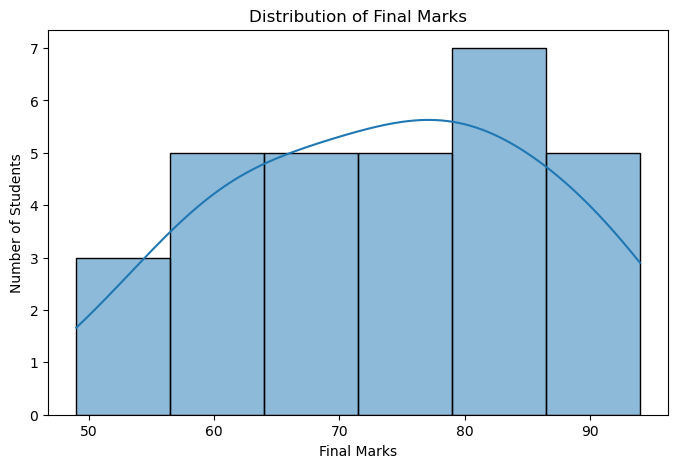

In [11]:
# Plot distribution of final marks

plt.figure(figsize=(8, 5))

sns.histplot(df['Final_Marks'], kde=True)

plt.title("Distribution of Final Marks")
plt.xlabel("Final Marks")
plt.ylabel("Number of Students")

plt.show()

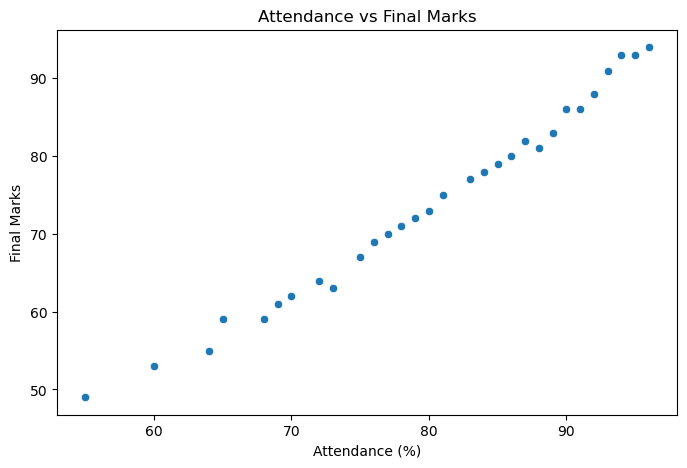

In [12]:
# Visualize the relationship between attendance and final marks

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='Attendance',
    y='Final_Marks',
    data=df
)

plt.title("Attendance vs Final Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("Final Marks")

plt.show()

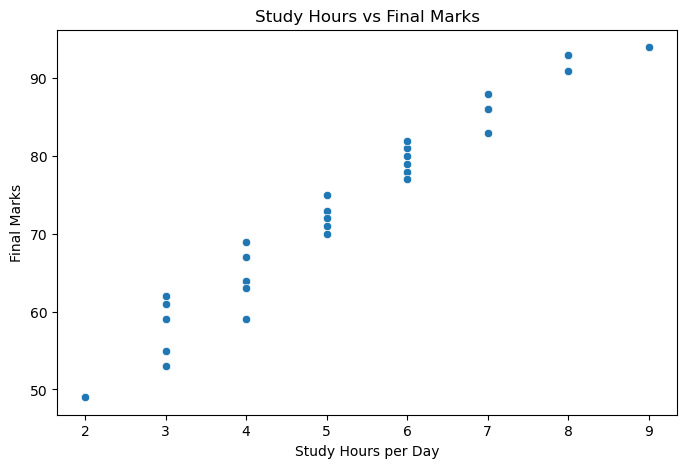

In [13]:
# Visualize the relationship between study hours and final marks

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='Study_Hours',
    y='Final_Marks',
    data=df
)

plt.title("Study Hours vs Final Marks")
plt.xlabel("Study Hours per Day")
plt.ylabel("Final Marks")

plt.show()

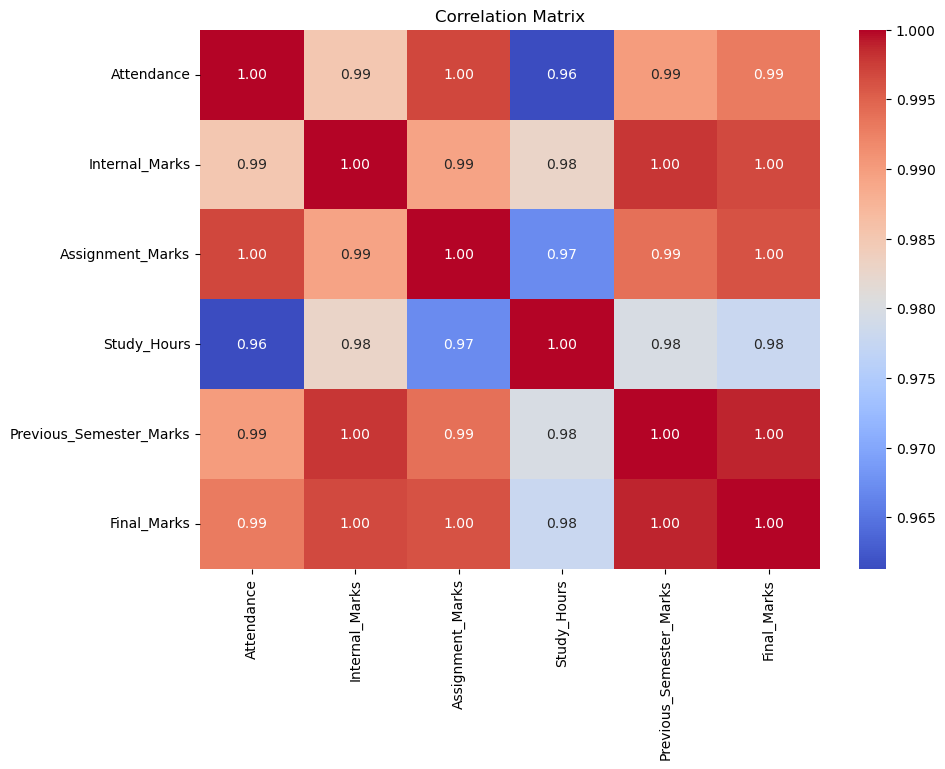

In [14]:
# Calculate correlation between all numerical variables

correlation_matrix = df.corr()

# Display correlation matrix

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix")

plt.show()

In [15]:
# X contains the input features
# y contains the target variable that we want to predict

X = df[
    [
        'Attendance',
        'Internal_Marks',
        'Assignment_Marks',
        'Study_Hours',
        'Previous_Semester_Marks'
    ]
]

# Target variable
y = df['Final_Marks']

# Display features
print("Features:")
print(X.head())

# Display target
print("\nTarget:")
print(y.head())

Features:
   Attendance  Internal_Marks  Assignment_Marks  Study_Hours  \
0          85              78                82            6   
1          90              85                88            7   
2          75              65                70            4   
3          95              92                95            8   
4          60              55                52            3   

   Previous_Semester_Marks  
0                       75  
1                       82  
2                       62  
3                       90  
4                       50  

Target:
0    79
1    86
2    67
3    93
4    53
Name: Final_Marks, dtype: int64


In [16]:
# Split the dataset into training and testing sets
#
# 80% data will be used for training
# 20% data will be used for testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data size:", X_train.shape)
print("Testing data size:", X_test.shape)

Training data size: (24, 5)
Testing data size: (6, 5)


In [17]:
# StandardScaler converts features into a common scale.
#
# This is especially useful when features have different ranges.
# For example:
# Attendance -> 0 to 100
# Study Hours -> 0 to 10

scaler = StandardScaler()

# Fit scaler on training data and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

In [18]:
# Create Linear Regression model

linear_model = LinearRegression()

# Train the model using training data

linear_model.fit(X_train_scaled, y_train)

# Predict final marks for test data

linear_predictions = linear_model.predict(X_test_scaled)

print("Linear Regression predictions:")
print(linear_predictions)

Linear Regression predictions:
[61.08889784 48.4091159  79.18099474 90.15058787 87.79030657 58.54425313]


In [19]:
# Calculate Mean Absolute Error
mae_linear = mean_absolute_error(y_test, linear_predictions)

# Calculate Mean Squared Error
mse_linear = mean_squared_error(y_test, linear_predictions)

# Calculate Root Mean Squared Error
rmse_linear = np.sqrt(mse_linear)

# Calculate R2 Score
r2_linear = r2_score(y_test, linear_predictions)

print("Linear Regression Performance")
print("--------------------------------")

print("MAE  :", round(mae_linear, 2))
print("MSE  :", round(mse_linear, 2))
print("RMSE :", round(rmse_linear, 2))
print("R²   :", round(r2_linear, 2))

Linear Regression Performance
--------------------------------
MAE  : 0.5
MSE  : 0.33
RMSE : 0.58
R²   : 1.0


In [20]:
# Create Decision Tree Regression model

decision_tree = DecisionTreeRegressor(
    random_state=42,
    max_depth=4
)

# Train the model

decision_tree.fit(X_train, y_train)

# Generate predictions

dt_predictions = decision_tree.predict(X_test)

print("Decision Tree predictions:")
print(dt_predictions)

Decision Tree predictions:
[63. 55. 78. 93. 86. 59.]


In [21]:
# Calculate evaluation metrics for Decision Tree

mae_dt = mean_absolute_error(y_test, dt_predictions)

mse_dt = mean_squared_error(y_test, dt_predictions)

rmse_dt = np.sqrt(mse_dt)

r2_dt = r2_score(y_test, dt_predictions)

print("Decision Tree Performance")
print("--------------------------------")

print("MAE  :", round(mae_dt, 2))
print("MSE  :", round(mse_dt, 2))
print("RMSE :", round(rmse_dt, 2))
print("R²   :", round(r2_dt, 2))

Decision Tree Performance
--------------------------------
MAE  : 2.33
MSE  : 8.67
RMSE : 2.94
R²   : 0.97


In [22]:
# Create Random Forest Regression model
#
# Random Forest combines multiple decision trees
# to improve prediction performance.

random_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    max_depth=5
)

# Train the Random Forest model

random_forest.fit(X_train, y_train)

# Predict final marks

rf_predictions = random_forest.predict(X_test)

print("Random Forest predictions:")
print(rf_predictions)

Random Forest predictions:
[61.1825 54.34   78.7075 91.53   85.91   58.565 ]


In [23]:
# Calculate evaluation metrics for Random Forest

mae_rf = mean_absolute_error(y_test, rf_predictions)

mse_rf = mean_squared_error(y_test, rf_predictions)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(y_test, rf_predictions)

print("Random Forest Performance")
print("--------------------------------")

print("MAE  :", round(mae_rf, 2))
print("MSE  :", round(mse_rf, 2))
print("RMSE :", round(rmse_rf, 2))
print("R²   :", round(r2_rf, 2))

Random Forest Performance
--------------------------------
MAE  : 1.65
MSE  : 5.84
RMSE : 2.42
R²   : 0.98


In [24]:
# Create a DataFrame to compare all models

model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'MAE': [
        mae_linear,
        mae_dt,
        mae_rf
    ],

    'MSE': [
        mse_linear,
        mse_dt,
        mse_rf
    ],

    'RMSE': [
        rmse_linear,
        rmse_dt,
        rmse_rf
    ],

    'R2 Score': [
        r2_linear,
        r2_dt,
        r2_rf
    ]
})

# Display results

model_comparison.round(2)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.50,0.33,0.58,1.00
1,Decision Tree,2.33,8.67,2.94,0.97
2,Random Forest,1.65,5.84,2.42,0.98


In [25]:
# Compare actual marks with Random Forest predictions

comparison = pd.DataFrame({
    'Actual Marks': y_test.values,
    'Predicted Marks': rf_predictions
})

# Display comparison

comparison

,Actual Marks,Predicted Marks
0,61,61.1825
1,49,54.3400
2,80,78.7075
3,91,91.5300
4,88,85.9100
5,59,58.5650


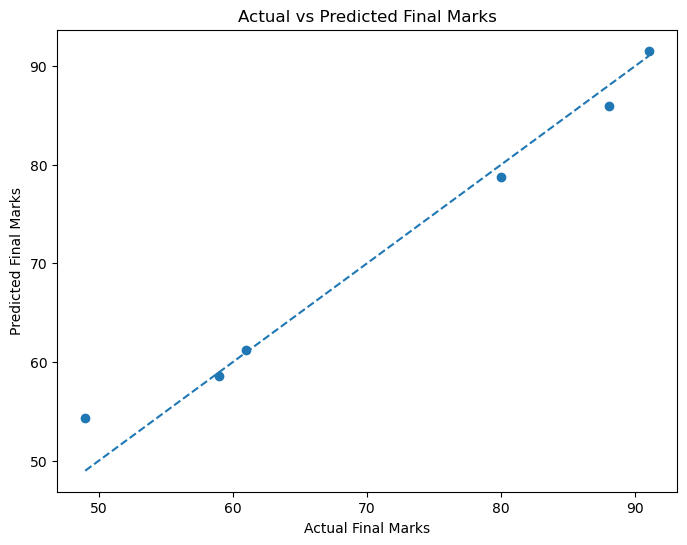

In [26]:
# Plot actual vs predicted values

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions
)

# Draw a reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Final Marks")
plt.ylabel("Predicted Final Marks")

plt.title("Actual vs Predicted Final Marks")

plt.show()

In [27]:
# Get feature importance from Random Forest

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': random_forest.feature_importances_
})

# Sort features by importance

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display feature importance

feature_importance

,Feature,Importance
0,Attendance,0.239105
4,Previous_Semester_Marks,0.224784
1,Internal_Marks,0.195490
2,Assignment_Marks,0.189719
3,Study_Hours,0.150901


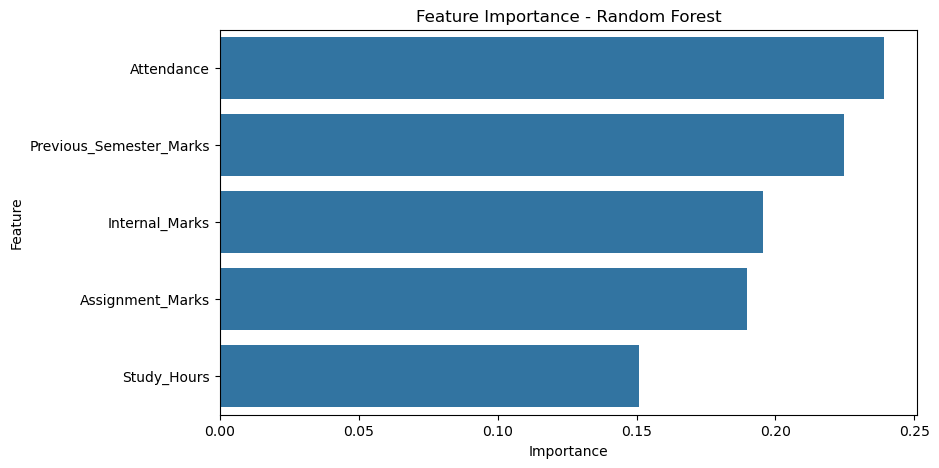

In [28]:
# Visualize feature importance

plt.figure(figsize=(9, 5))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance
)

plt.title("Feature Importance - Random Forest")

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [29]:
# Create data for a new student

new_student = pd.DataFrame({
    'Attendance': [88],
    'Internal_Marks': [82],
    'Assignment_Marks': [85],
    'Study_Hours': [6],
    'Previous_Semester_Marks': [80]
})

# Display new student's information

new_student

,Attendance,Internal_Marks,Assignment_Marks,Study_Hours,Previous_Semester_Marks
0,88,82,85,6,80


In [30]:
# Use the trained Random Forest model
# to predict the final marks of the new student

new_prediction = random_forest.predict(new_student)

print(
    "Predicted Final Marks:",
    round(new_prediction[0], 2)
)

Predicted Final Marks: 81.66


In [31]:
# Convert predicted marks into a simple performance category

predicted_marks = new_prediction[0]

if predicted_marks >= 75:
    performance = "Excellent"
elif predicted_marks >= 60:
    performance = "Good"
elif predicted_marks >= 50:
    performance = "Average"
else:
    performance = "Needs Improvement"

print("Predicted Final Marks:", round(predicted_marks, 2))
print("Performance Category:", performance)

Predicted Final Marks: 81.66
Performance Category: Excellent


In [32]:
print("Student Performance Prediction System")
print("---------------------------------------")

print("The machine learning system predicts a student's")
print("final academic performance using:")
print("1. Attendance")
print("2. Internal Marks")
print("3. Assignment Marks")
print("4. Study Hours")
print("5. Previous Semester Marks")

print("\nThree regression models were trained:")
print("1. Linear Regression")
print("2. Decision Tree Regression")
print("3. Random Forest Regression")

print("\nThe models were evaluated using:")
print("MAE, MSE, RMSE and R² Score.")

print("\nThe trained model can be used to estimate")
print("the final marks and performance category of a new student.")

Student Performance Prediction System
---------------------------------------
The machine learning system predicts a student's
final academic performance using:
1. Attendance
2. Internal Marks
3. Assignment Marks
4. Study Hours
5. Previous Semester Marks

Three regression models were trained:
1. Linear Regression
2. Decision Tree Regression
3. Random Forest Regression

The models were evaluated using:
MAE, MSE, RMSE and R² Score.

The trained model can be used to estimate
the final marks and performance category of a new student.
